# Statistical Learning — Bias, Variance & Error

We explore the **bias-variance trade-off**, measure prediction error three ways, and fit a multiple regression with hypothesis tests.

## How this notebook works

<table>
<tr><td style="font-size:1.4em;">🧮</td><td><b style="color:#E37222;">Level 1 · By hand</b></td><td>Do the math yourself on small <b>mock data</b> — plain arithmetic, no libraries.</td></tr>
<tr><td style="font-size:1.4em;">🐍</td><td><b style="color:#0065BD;">Level 2 · With NumPy</b></td><td>Implement the formula with basic <b>NumPy</b> on the real data.</td></tr>
<tr><td style="font-size:1.4em;">📚</td><td><b style="color:#5E6A00;">Level 3 · With libraries</b></td><td>Use <b>pandas / scikit-learn</b> — the practical way.</td></tr>
</table>

Not every topic offers all three levels — the foundational ones do, later applied ones jump straight to the practical level. When stuck, expand a hint: <b>💡 Hint</b> names the functions (with docs); <b>🔑 Stuck?</b> shows them on mock data.

## Setup &mdash; packages and data

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
plt.style.use(os.path.join(os.getcwd(), "..", "..", "configs", "visualisations.mplstyle"))
df = pd.read_csv(os.path.join("..", "..", "data", "1900_2021_DISASTERS.csv"))

df['Total Damages (US$)'] = df["Total Damages ('000 US$)"] * 1000
df['date'] = pd.to_datetime(
    dict(year=df['Start Year'], month=df['Start Month'].fillna(1).astype(int),
         day=df['Start Day'].fillna(1).astype(int)),
    errors='coerce')
df.head(5)

,Year,Seq,Glide,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,Disaster Subsubtype,Event Name,Country,...,Total Affected,Insured Damages ('000 US$),Total Damages ('000 US$),CPI,Adm Level,Admin1 Code,Admin2 Code,Geo Locations,Total Damages (US$),date
0,1900,9002,NaN,Natural,Climatological,Drought,Drought,NaN,NaN,Cabo Verde,...,NaN,NaN,NaN,3.221647,NaN,NaN,NaN,NaN,NaN,1900-01-01
1,1900,9001,NaN,Natural,Climatological,Drought,Drought,NaN,NaN,India,...,NaN,NaN,NaN,3.221647,NaN,NaN,NaN,NaN,NaN,1900-01-01
2,1902,12,NaN,Natural,Geophysical,Earthquake,Ground movement,NaN,NaN,Guatemala,...,NaN,NaN,25000.0,3.350513,NaN,NaN,NaN,NaN,25000000.0,1902-04-18
3,1902,3,NaN,Natural,Geophysical,Volcanic activity,Ash fall,NaN,Santa Maria,Guatemala,...,NaN,NaN,NaN,3.350513,NaN,NaN,NaN,NaN,NaN,1902-04-08
4,1902,10,NaN,Natural,Geophysical,Volcanic activity,Ash fall,NaN,Santa Maria,Guatemala,...,NaN,NaN,NaN,3.350513,NaN,NaN,NaN,NaN,NaN,1902-10-24


# The bias-variance trade-off

### Fitting a polynomial
A high-degree polynomial fits the training scatter ever more closely — but starts to chase noise (high variance).

<div style="background-color:#E8F1FA; border-left:6px solid #0065BD; padding:8px 14px; border-radius:6px; margin:6px 0;"><b style="font-size:1.05em; color:#0065BD;">🐍&nbsp; Level 2 · With NumPy</b><br><span style="color:#000;">Fit a polynomial of <code>degree = 20</code> to the (log-log) scatter with NumPy and draw the fitted curve on top.</span></div>

<details>
<summary>💡 <b>Hint</b> &mdash; which functions to use</summary>

Get coefficients with [`np.polyfit`](https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html)`(x, y, degree)`, build a callable with [`np.poly1d`](https://numpy.org/doc/stable/reference/generated/numpy.poly1d.html), evaluate it over [`np.linspace`](https://numpy.org/doc/stable/reference/generated/numpy.linspace.html)`(x.min(), x.max(), 100)`.

</details>

/var/folders/ct/qpfxjbdn1xx4fvb2v099sg_00000gn/T/ipykernel_19091/4246255864.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(); plt.xlabel(x_axis); plt.ylabel(y_axis); plt.title(f'Scatterplot of {x_axis} vs. {y_axis}'); plt.show()


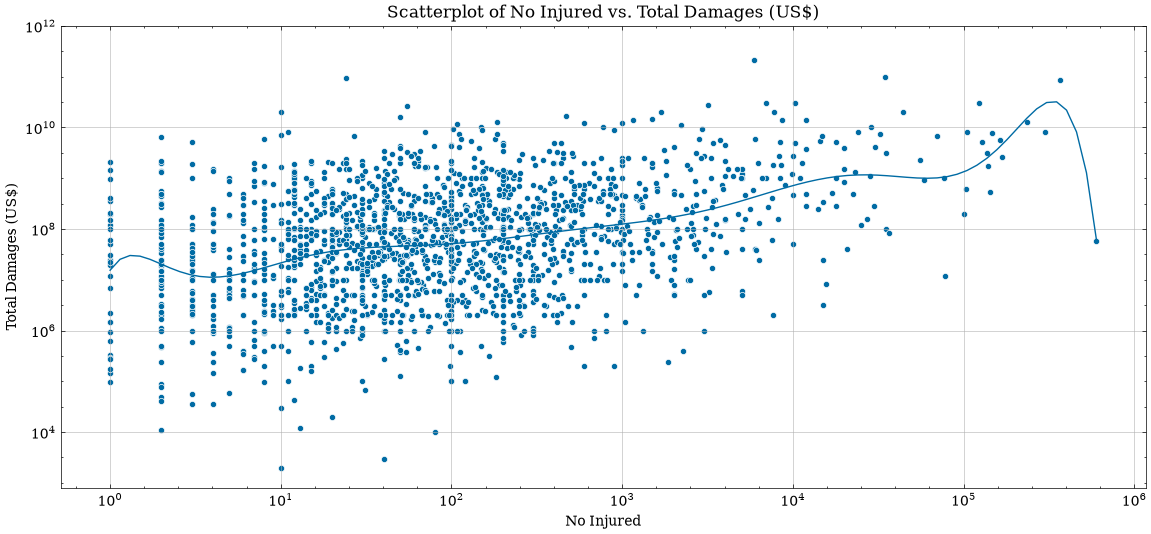

In [7]:
x_axis = 'No Injured'
y_axis = 'Total Damages (US$)'
degree = 10

mask = (df[x_axis] > 0) & (df[y_axis] > 0)
x = np.log10(df.loc[mask, x_axis])
y = np.log10(df.loc[mask, y_axis])
plt.scatter(x, y, s=20, marker='o', alpha=1, edgecolors='w', linewidth=0.5)

# ---- YOUR CODE GOES HERE (START) ---
coeffiecients = np.polyfit(x,y, degree)
poly = np.poly1d(coeffiecients)
x_fit = np.linspace(x.min(), x.max(), 100)
plt.plot(x_fit, poly(x_fit),)

# --- YOUR CODE GOES HERE (END) ---

plt.xticks(ticks=np.log10([1e0, 1e1, 1e2, 1e3, 1e4, 1e5, 1e6]), labels=['$10^0$', '$10^1$', '$10^2$', '$10^3$', '$10^4$', '$10^5$', '$10^6$'])
plt.yticks(ticks=np.log10([1e4, 1e6, 1e8, 1e10, 1e12]), labels=['$10^4$', '$10^6$', '$10^8$', '$10^{10}$', '$10^{12}$'])
plt.legend(); plt.xlabel(x_axis); plt.ylabel(y_axis); plt.title(f'Scatterplot of {x_axis} vs. {y_axis}'); plt.show()

# Measuring error — MAE, MSE, RMSE

<div style="background-color:#FCEEE3; border-left:6px solid #E37222; padding:8px 14px; border-radius:6px; margin:6px 0;"><b style="font-size:1.05em; color:#E37222;">🧮&nbsp; Level 1 · By hand</b><br><span style="color:#000;">For true values <code>y_true = [2, 4, 6]</code> and predictions <code>y_hat = [3, 4, 5]</code> (residuals −1, 0, +1), compute the <b>MAE</b> (mean absolute error), <b>MSE</b> (mean squared error) and <b>RMSE</b> (√MSE) by hand.</span></div>

In [8]:
y_true = [2.0, 4.0, 6.0]
y_hat = [3.0, 4.0, 5.0]   # residuals: -1, 0, +1

# ---- YOUR CODE GOES HERE (START) ---
mae_h = (1 + 0 + 1)/3
mse_h = (1 + 0 + 1)/3
rmse_h = mse_h **0.5

# --- YOUR CODE GOES HERE (END) ---

print(f'MAE = {mae_h:.3f}, MSE = {mse_h:.3f}, RMSE = {rmse_h:.3f}')

MAE = 0.667, MSE = 0.667, RMSE = 0.816


<div style="background-color:#E8F1FA; border-left:6px solid #0065BD; padding:8px 14px; border-radius:6px; margin:6px 0;"><b style="font-size:1.05em; color:#0065BD;">🐍&nbsp; Level 2 · With NumPy</b><br><span style="color:#000;">Now compute the MAE, MSE and RMSE of the degree-20 fit using <b>only NumPy</b>, and compare to scikit-learn's <code>sklearn.metrics</code>.</span></div>

<details>
<summary>💡 <b>Hint</b> &mdash; which functions to use</summary>

Residuals are `y - y_pred`; use [`np.abs`](https://numpy.org/doc/stable/reference/generated/numpy.absolute.html), [`np.average`](https://numpy.org/doc/stable/reference/generated/numpy.average.html) (or [`np.mean`](https://numpy.org/doc/stable/reference/generated/numpy.mean.html)), and [`np.sqrt`](https://numpy.org/doc/stable/reference/generated/numpy.sqrt.html).

</details>

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error
x_axis = 'No Injured'
y_axis = 'Total Damages (US$)'
degree = 10

mask = (df[x_axis] > 0) & (df[y_axis] > 0)
x = np.log10(df.loc[mask, x_axis])
y = np.log10(df.loc[mask, y_axis])

# ---- YOUR CODE GOES HERE (START) ---
coeffiecients = np.polyfit(x,y, degree)
poly = np.poly1d(coeffiecients)

y_pred = poly(x)

# ---- YOUR CODE GOES HERE (START) ---
residuals = y -y_pred
mae = np.abs(residuals)
mse = np.average((y -y_pred)**2)
rmse = np.sqrt(mse)

# --- YOUR CODE GOES HERE (END) ---

sk_mae = mean_absolute_error(y, y_pred)
sk_mse = mean_squared_error(y, y_pred)
sk_rmse = root_mean_squared_error(y, y_pred)
print(f"MAE: {mae.mean():.4f} (sklearn: {sk_mae:.4f})")
print(f"MSE: {mse:.4f} (sklearn: {sk_mse:.4f})")
print(f"RMSE: {rmse:.4f} (sklearn: {sk_rmse:.4f})")

MAE: 0.8400 (sklearn: 0.8400)
MSE: 1.1039 (sklearn: 1.1039)
RMSE: 1.0507 (sklearn: 1.0507)


# Linear regression & hypothesis testing

### Multiple regression with statsmodels

<div style="background-color:#F1F3DD; border-left:6px solid #5E6A00; padding:8px 14px; border-radius:6px; margin:6px 0;"><b style="font-size:1.05em; color:#5E6A00;">📚&nbsp; Level 3 · With libraries</b><br><span style="color:#000;">Fit a multiple linear regression of log <code>Total Damages</code> on three log predictors with <code>statsmodels</code>, and read the coefficient hypothesis tests from the summary.</span></div>

<details>
<summary>💡 <b>Hint</b> &mdash; which functions to use</summary>

Add an intercept with [`sm.add_constant`](https://www.statsmodels.org/stable/generated/statsmodels.tools.tools.add_constant.html), fit with [`sm.OLS`](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLS.html)`(y, X).fit()`, and print `.summary()`.

</details>

In [ ]:
import statsmodels.api as sm

features = ["Total Deaths", "No Homeless", "No Injured"]
target = "Total Damages (US$)"
X = np.log10(df[features])
y = np.log10(df[target])
valid = ~(X.isnull().any(axis=1) | X.isin([np.inf, -np.inf]).any(axis=1) | y.isnull() | y.isin([np.inf, -np.inf]))
X = X[valid]
y = y[valid]

# ---- YOUR CODE GOES HERE (START) ---

# --- YOUR CODE GOES HERE (END) ---